<a href="https://colab.research.google.com/github/GuilhermeNunesP/Trabalhos-de-python/blob/main/Trabalho_Analise_de_Dados_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

In [2]:
print("Envie o arquivo Nintendo_Analise_de_Dados_v2.xlsx")
arquivos = files.upload()

arquivo = next(iter(arquivos))


df = pd.read_excel(arquivo, sheet_name="Jogos")


colunas_texto = [
    "nome_jogo",
    "genero",
    "genero_detalhado",
    "franquia",
    "sub_franquia",
    "plataforma_original",
    "desenvolvedora_principal",
    "sub_desenvolvedora"
]

for coluna in colunas_texto:
    if coluna in df.columns:
        df[coluna] = df[coluna].astype("string").str.strip()


colunas_numericas = [
    "ano_lancamento",
    "vendas_milhoes",
    "nota_critica_100",
    "nota_publico_100"
]

for coluna in colunas_numericas:
    if coluna in df.columns:
        df[coluna] = pd.to_numeric(df[coluna], errors="coerce")


print(f"\nPlanilha carregada: {len(df)} jogos")
print("Colunas:", df.columns.tolist())

display(df)

Envie o arquivo Nintendo_Analise_de_Dados_v2.xlsx


Saving Nintendo_Analise_de_Dados_v2.xlsx to Nintendo_Analise_de_Dados_v2.xlsx

Planilha carregada: 540 jogos
Colunas: ['id', 'nome_jogo', 'ano_lancamento', 'genero', 'genero_detalhado', 'plataforma_original', 'franquia_principal', 'sub_franquia', 'desenvolvedora_principal', 'sub_desenvolvedora', 'vendas_milhoes', 'nota_critica_100', 'nota_publico_100']


,id,nome_jogo,ano_lancamento,genero,genero_detalhado,plataforma_original,franquia_principal,sub_franquia,desenvolvedora_principal,sub_desenvolvedora,vendas_milhoes,nota_critica_100,nota_publico_100
0,J0024,Donkey Kong,1982,Ação,Ação e reflexos,Nintendo Game & Watch,Mario,Donkey Kong,Nintendo,<NA>,NaN,NaN,NaN
1,J0036,Donkey Kong 3,1983,Ação,Tiro e arcade,Arcade,Mario,Donkey Kong,Nintendo,<NA>,NaN,NaN,NaN
2,J0045,Donkey Kong 3,1984,Ação,Ação e reflexos,Nintendo Game & Watch,Mario,Donkey Kong,Nintendo,<NA>,NaN,NaN,NaN
3,J0044,Donkey Kong Circus,1984,Ação,Ação e equilíbrio,Nintendo Game & Watch,Mario,Donkey Kong,Nintendo,<NA>,NaN,NaN,NaN
4,J0035,Donkey Kong II,1983,Ação,Ação e reflexos,Nintendo Game & Watch,Mario,Donkey Kong,Nintendo,<NA>,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
535,J0349,Nintendogs + Cats,2011,Simulação,Simulação de animais de estimação,Nintendo 3DS,Nintendogs,<NA>,Nintendo EAD,<NA>,NaN,71.0,NaN
536,J0330,Okaeri! Chibi-Robo! Happy Richie Ōsōji!,2009,Simulação,Aventura e simulação,Nintendo DS,Chibi-Robo!,<NA>,Skip Ltd.,<NA>,NaN,NaN,NaN
537,J0313,Tomodachi Collection,2009,Simulação,Simulação social,Nintendo DS,Tomodachi Life,<NA>,Nintendo SPD,<NA>,3.20,71.0,81.0
538,J0386,Tomodachi Life,2013,Simulação,Simulação social,Nintendo 3DS,Tomodachi Life,<NA>,Nintendo SPD,<NA>,6.72,NaN,NaN


In [3]:
print("DIMENSÕES DA BASE")
print("Quantidade de jogos:", len(df))
print("Quantidade de colunas:", len(df.columns))

print("\nTIPOS DE DADOS")
print(df.dtypes)

print("\nVALORES AUSENTES POR COLUNA")
print(df.isna().sum())

print("\nLINHAS DUPLICADAS")
print(df.duplicated().sum())

print("\nJOGOS COM NOMES REPETIDOS")
print(df["nome_jogo"].duplicated().sum())

print("\nRESUMO ESTATÍSTICO")
display(df.describe(include="all").T)

DIMENSÕES DA BASE
Quantidade de jogos: 540
Quantidade de colunas: 13

TIPOS DE DADOS
id                                  object
nome_jogo                   string[python]
ano_lancamento                       int64
genero                      string[python]
genero_detalhado            string[python]
plataforma_original         string[python]
franquia_principal                  object
sub_franquia                string[python]
desenvolvedora_principal    string[python]
sub_desenvolvedora          string[python]
vendas_milhoes                     float64
nota_critica_100                   float64
nota_publico_100                   float64
dtype: object

VALORES AUSENTES POR COLUNA
id                            0
nome_jogo                     0
ano_lancamento                0
genero                        0
genero_detalhado              0
plataforma_original           0
franquia_principal            0
sub_franquia                266
desenvolvedora_principal      0
sub_desenvolvedora       

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,540,540,J0537,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nome_jogo,540,525,Punch-Out!!,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ano_lancamento,540.0,NaN,NaN,NaN,2005.222222,11.749025,1980.0,1998.0,2007.0,2015.0,2026.0
genero,540,14,RPG,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero_detalhado,540,153,Ação e reflexos,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plataforma_original,540,34,Nintendo Switch,65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
franquia_principal,540,39,Mario,196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sub_franquia,274,44,Donkey Kong,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
desenvolvedora_principal,540,78,Nintendo,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sub_desenvolvedora,49,27,Intelligent Systems,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


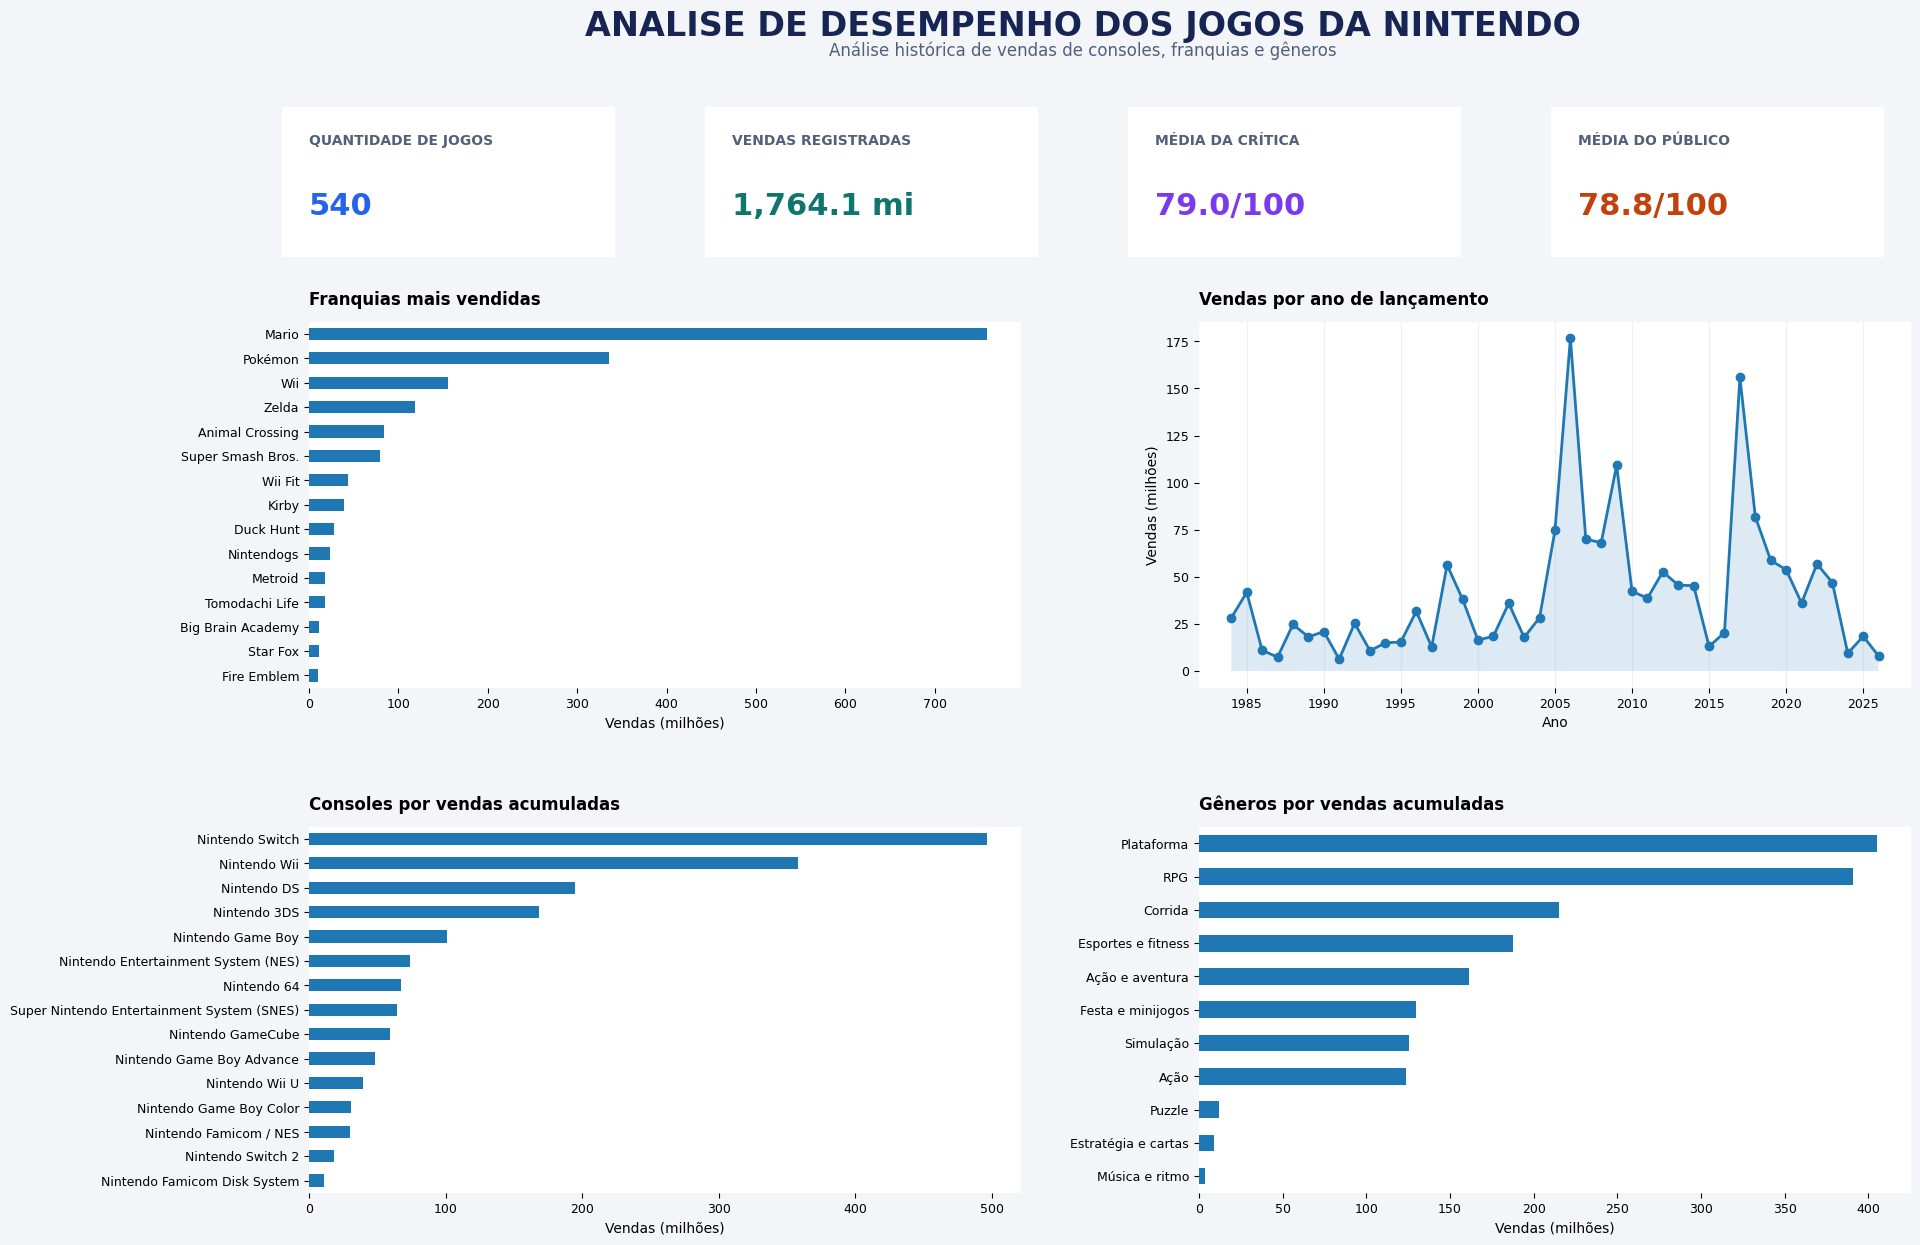

In [54]:


dados = df.copy()

colunas_numericas = [
    "ano_lancamento",
    "vendas_milhoes",
    "nota_critica_100",
    "nota_publico_100"
]

for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(
        dados[coluna], errors="coerce"
    )

colunas_texto = [
    "franquia_principal",
    "plataforma_original",
    "genero"
]

for coluna in colunas_texto:
    dados[coluna] = (
        dados[coluna]
        .astype("string")
        .str.strip()
    )


dados.loc[dados["vendas_milhoes"] < 0, "vendas_milhoes"] = np.nan


for coluna in ["nota_critica_100", "nota_publico_100"]:
    dados.loc[
        ~dados[coluna].between(0, 100),
        coluna
    ] = np.nan



total_jogos = len(dados)

vendas_totais = dados["vendas_milhoes"].sum()

media_critica = dados["nota_critica_100"].mean()
media_publico = dados["nota_publico_100"].mean()



def ranking_soma(coluna):
    base = dados.dropna(subset=[coluna, "vendas_milhoes"])
    base = base[base[coluna].ne("")]
    return (
        base.groupby(coluna)["vendas_milhoes"]
        .sum()
        .sort_values(ascending=False)
    )

def ranking_media(coluna_nota, categoria):
    base = dados.dropna(subset=[coluna_nota, categoria])
    base = base[base[categoria].ne("")]
    return (
        base.groupby(categoria)[coluna_nota]
        .mean()
        .sort_values(ascending=False)
    )

franquias = ranking_soma("franquia_principal").head(15)
consoles = ranking_soma("plataforma_original").head(15)
generos = ranking_soma("genero").head(12)

vendas_ano = (
    dados.dropna(subset=["ano_lancamento", "vendas_milhoes"])
    .groupby("ano_lancamento")["vendas_milhoes"]
    .sum()
    .sort_index()
)



fig = plt.figure(figsize=(18, 13), facecolor="#F3F5F9")

fig.suptitle(
    "ANALISE DE DESEMPENHO DOS JOGOS DA NINTENDO",
    fontsize=24,
    fontweight="bold",
    color="#172554",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "Análise histórica de vendas de consoles, franquias e gêneros",
    ha="center",
    fontsize=12,
    color="#526079"
)


indicadores = [
    ("QUANTIDADE DE JOGOS", f"{total_jogos:,}", "#2563EB"),
    ("VENDAS REGISTRADAS", f"{vendas_totais:,.1f} mi", "#0F766E"),
    (
        "MÉDIA DA CRÍTICA",
        f"{media_critica:.1f}/100" if pd.notna(media_critica) else "N/D",
        "#7C3AED"
    ),
    (
        "MÉDIA DO PÚBLICO",
        f"{media_publico:.1f}/100" if pd.notna(media_publico) else "N/D",
        "#C2410C"
    )
]

posicoes = [0.055, 0.29, 0.525, 0.76]

for i, (titulo, valor, cor) in enumerate(indicadores):
    ax_card = fig.add_axes([posicoes[i], 0.79, 0.185, 0.115])
    ax_card.set_facecolor("white")
    ax_card.set_xticks([])
    ax_card.set_yticks([])

    for borda in ax_card.spines.values():
        borda.set_visible(False)

    ax_card.text(
        0.08, 0.75, titulo,
        transform=ax_card.transAxes,
        fontsize=10,
        color="#526079",
        fontweight="bold"
    )

    ax_card.text(
        0.08, 0.28, valor,
        transform=ax_card.transAxes,
        fontsize=22,
        color=cor,
        fontweight="bold"
    )


gs = fig.add_gridspec(
    2, 2,
    left=0.07,
    right=0.96,
    bottom=0.07,
    top=0.74,
    hspace=0.38,
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

eixos = [ax1, ax2, ax3, ax4]

for ax in eixos:
    ax.set_facecolor("white")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)


if not franquias.empty:
    franquias.sort_values().plot(
        kind="barh", ax=ax1
    )
    ax1.set_title(
        "Franquias mais vendidas",
        loc="left", fontweight="bold", pad=12
    )
    ax1.set_xlabel("Vendas (milhões)")
    ax1.set_ylabel("")
else:
    ax1.text(0.5, 0.5, "Sem dados disponíveis", ha="center")


if not vendas_ano.empty:
    ax2.plot(
        vendas_ano.index,
        vendas_ano.values,
        marker="o",
        linewidth=2
    )
    ax2.fill_between(
        vendas_ano.index,
        vendas_ano.values,
        alpha=0.15
    )
    ax2.set_title(
        "Vendas por ano de lançamento",
        loc="left", fontweight="bold", pad=12
    )
    ax2.set_xlabel("Ano")
    ax2.set_ylabel("Vendas (milhões)")
    ax2.xaxis.set_major_locator(MaxNLocator(integer=True))
else:
    ax2.text(0.5, 0.5, "Sem dados disponíveis", ha="center")


if not consoles.empty:
    consoles.sort_values().plot(
        kind="barh", ax=ax3
    )
    ax3.set_title(
        "Consoles por vendas acumuladas",
        loc="left", fontweight="bold", pad=12
    )
    ax3.set_xlabel("Vendas (milhões)")
    ax3.set_ylabel("")
else:
    ax3.text(0.5, 0.5, "Sem dados disponíveis", ha="center")


if not generos.empty:
    generos.sort_values().plot(
        kind="barh", ax=ax4
    )
    ax4.set_title(
        "Gêneros por vendas acumuladas",
        loc="left", fontweight="bold", pad=12
    )
    ax4.set_xlabel("Vendas (milhões)")
    ax4.set_ylabel("")
else:
    ax4.text(0.5, 0.5, "Sem dados disponíveis", ha="center")


for ax in eixos:
    ax.tick_params(axis="both", labelsize=9)
    for borda in ax.spines.values():
        borda.set_visible(False)



plt.show()


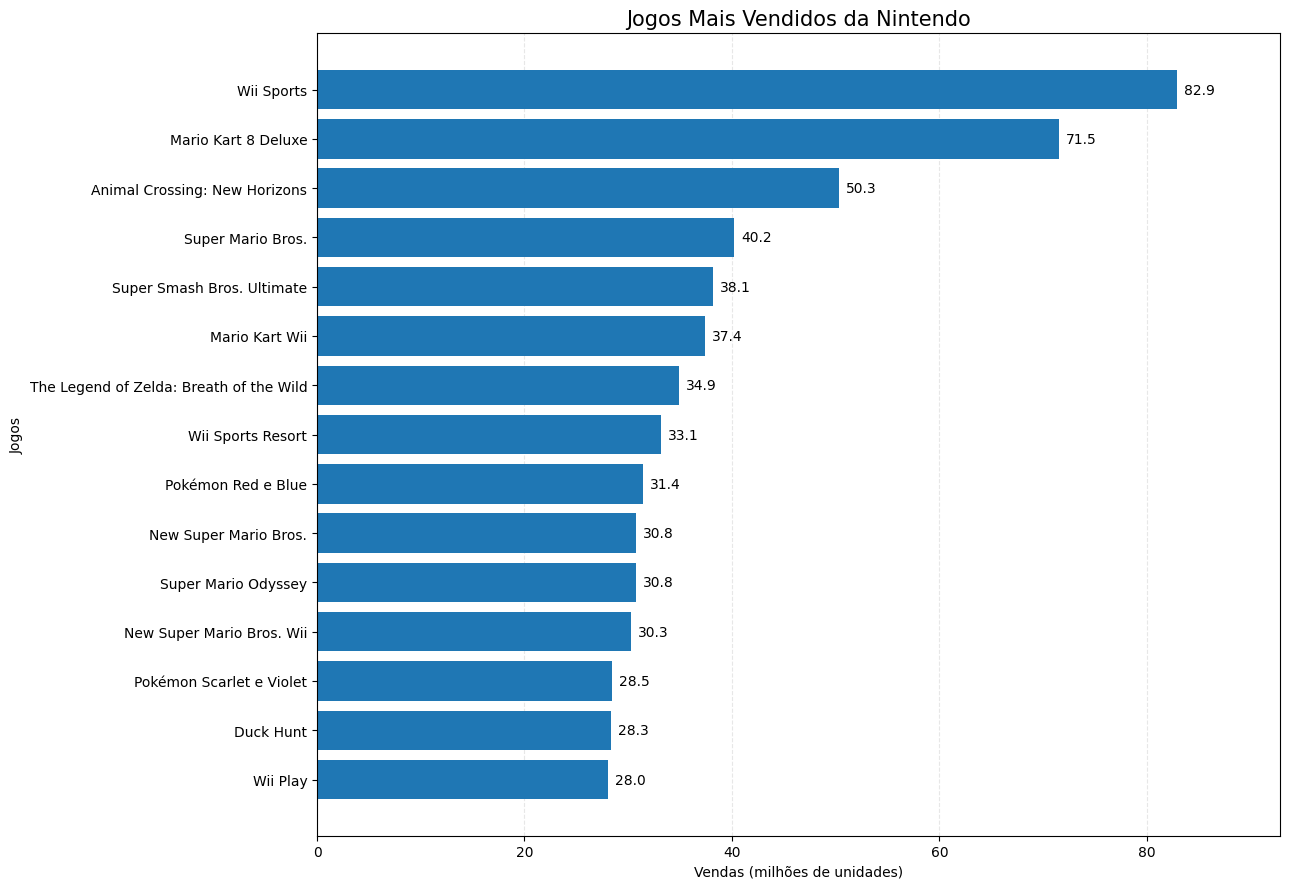

In [55]:




df["vendas_milhoes"] = pd.to_numeric(
    df["vendas_milhoes"], errors="coerce"
)

dados = df.dropna(
    subset=["nome_jogo", "vendas_milhoes"]
).copy()


dados = dados[dados["vendas_milhoes"] >= 0]


top_15 = (
    dados.sort_values("vendas_milhoes", ascending=False)
    .head(15)
    .sort_values("vendas_milhoes", ascending=True)
)


fig, ax = plt.subplots(figsize=(13, 9))

barras = ax.barh(
    top_15["nome_jogo"],
    top_15["vendas_milhoes"]
)


ax.bar_label(
    barras,
    labels=[f"{v:,.1f}" for v in top_15["vendas_milhoes"]],
    padding=5,
    fontsize=10
)

ax.set_title("Jogos Mais Vendidos da Nintendo", fontsize=15)
ax.set_xlabel("Vendas (milhões de unidades)")
ax.set_ylabel("Jogos")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.margins(x=0.12)

plt.tight_layout()
plt.show()






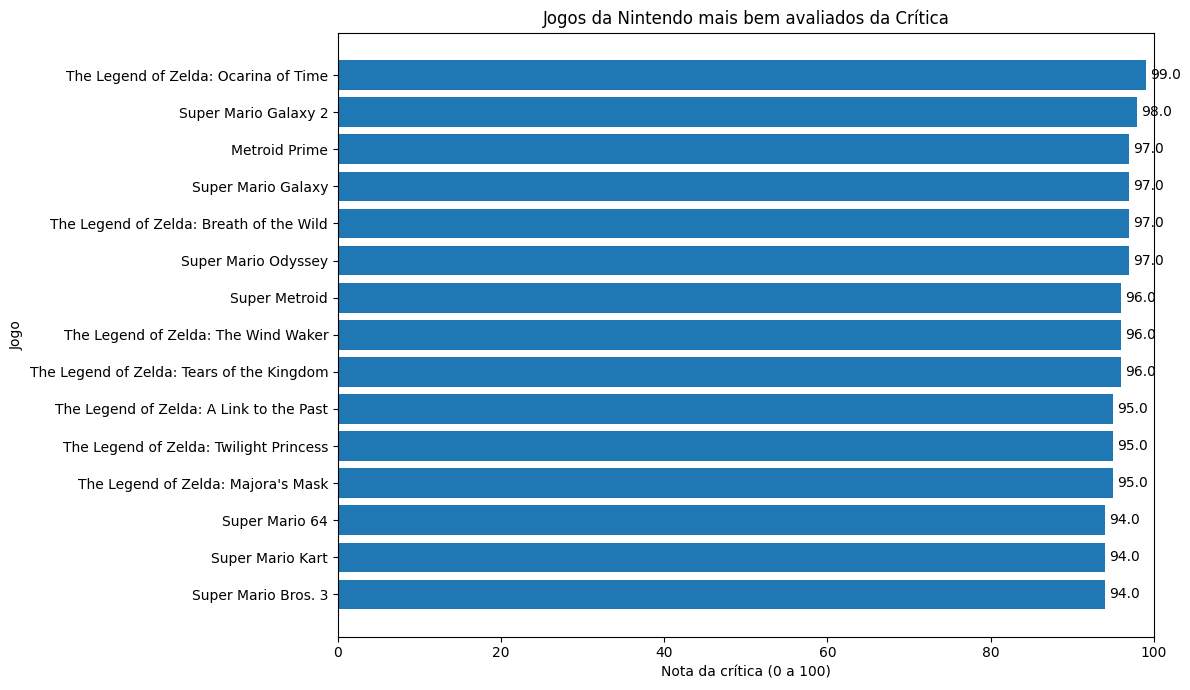

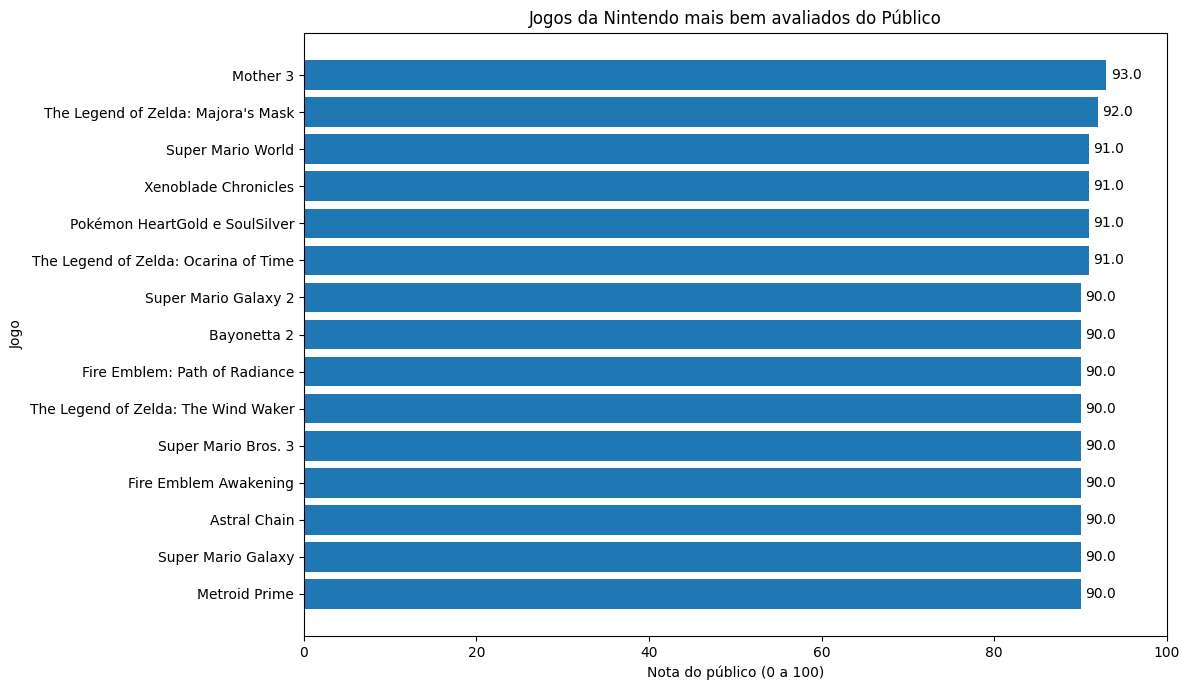

In [56]:
dados = df.copy()


dados["nota_critica_100"] = pd.to_numeric(
    dados["nota_critica_100"], errors="coerce"
)

dados["nota_publico_100"] = pd.to_numeric(
    dados["nota_publico_100"], errors="coerce"
)


colunas = [
    "nome_jogo",
    "ano_lancamento",
    "plataforma_original",
    "nota_critica_100",
    "nota_publico_100"
]


top_critica = (
    dados.dropna(subset=["nota_critica_100"])
    .sort_values(
        by="nota_critica_100",
        ascending=False
    )
    .head(15)
)




grafico_critica = top_critica.sort_values(
    "nota_critica_100", ascending=True
)

plt.figure(figsize=(12, 7))
plt.barh(
    grafico_critica["nome_jogo"],
    grafico_critica["nota_critica_100"]
)

plt.title("Jogos da Nintendo mais bem avaliados da Crítica")
plt.xlabel("Nota da crítica (0 a 100)")
plt.ylabel("Jogo")
plt.xlim(0, 100)

for i, nota in enumerate(grafico_critica["nota_critica_100"]):
    plt.text(nota + 0.5, i, f"{nota:.1f}", va="center")

plt.tight_layout()
plt.show()


top_publico = (
    dados.dropna(subset=["nota_publico_100"])
    .sort_values(
        by="nota_publico_100",
        ascending=False
    )
    .head(15)
)




grafico_publico = top_publico.sort_values(
    "nota_publico_100", ascending=True
)

plt.figure(figsize=(12, 7))
plt.barh(
    grafico_publico["nome_jogo"],
    grafico_publico["nota_publico_100"]
)

plt.title("Jogos da Nintendo mais bem avaliados do Público")
plt.xlabel("Nota do público (0 a 100)")
plt.ylabel("Jogo")
plt.xlim(0, 100)

for i, nota in enumerate(grafico_publico["nota_publico_100"]):
    plt.text(nota + 0.5, i, f"{nota:.1f}", va="center")

plt.tight_layout()
plt.show()


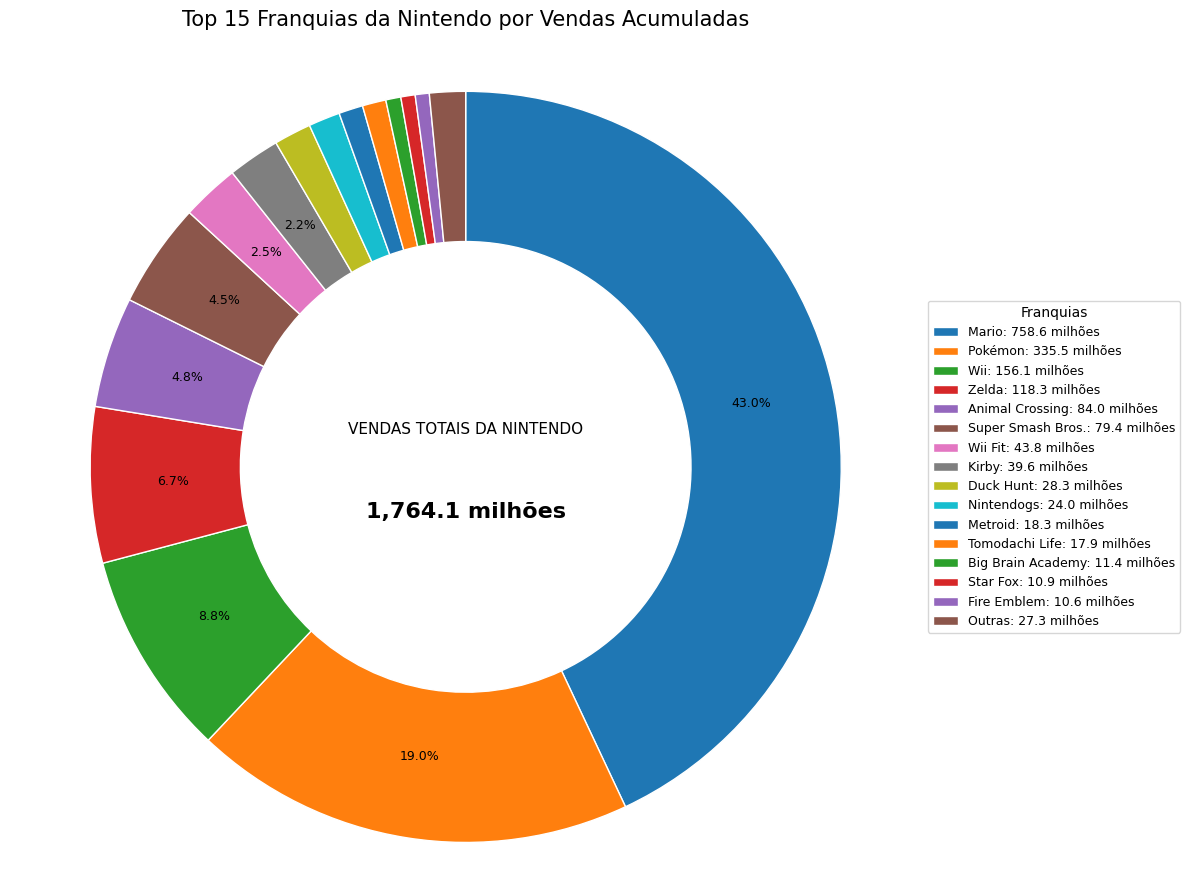

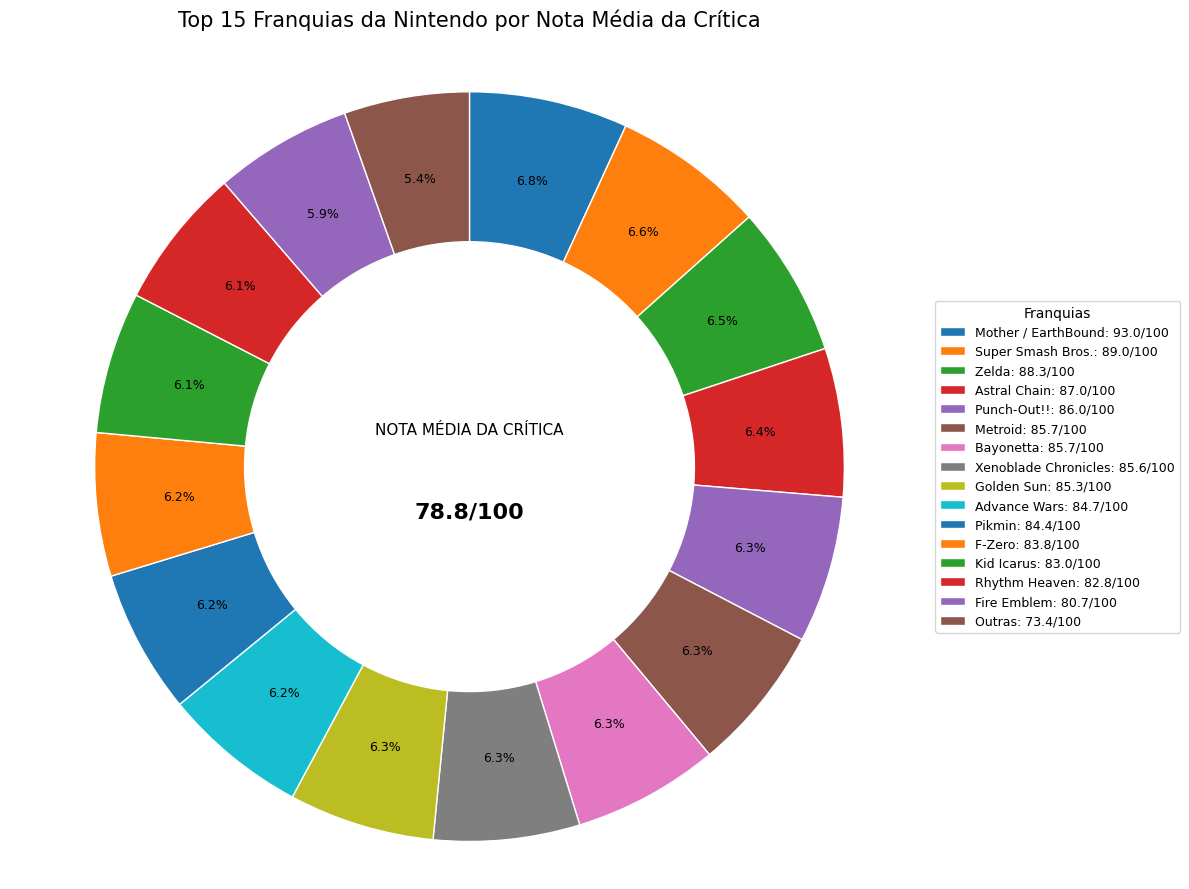

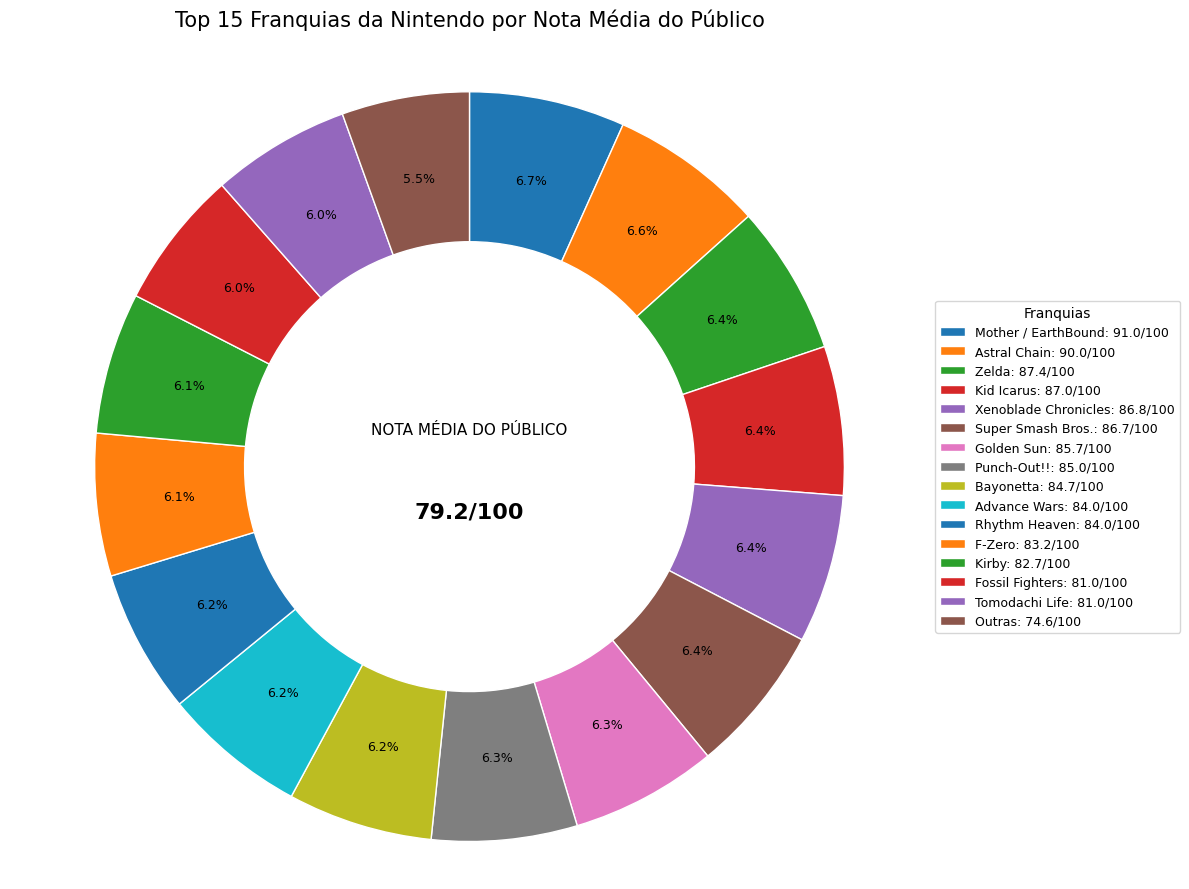

In [57]:




df["vendas_milhoes"] = pd.to_numeric(
    df["vendas_milhoes"], errors="coerce"
)


dados = df.copy()
dados["franquia_principal"] = (
    dados["franquia_principal"].astype("string").str.strip()
)


dados = dados[
    dados["franquia_principal"].notna()
    & dados["franquia_principal"].ne("")
    & dados["vendas_milhoes"].notna()
    & (dados["vendas_milhoes"] >= 0)
]


vendas_franquias = (
    dados.groupby("franquia_principal")["vendas_milhoes"]
    .sum()
    .sort_values(ascending=False)
)


top_15 = vendas_franquias.head(15)


outras = vendas_franquias.iloc[15:].sum()

if outras > 0:
    grafico = pd.concat([
        top_15,
        pd.Series({"Outras": outras})
    ])
else:
    grafico = top_15


fig, ax = plt.subplots(figsize=(12, 9))

ax.pie(
    grafico.values,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.40,
        "edgecolor": "white"
    },
    textprops={"fontsize": 9}
)


total_vendas = vendas_franquias.sum()


ax.text(
    0, 0.10,
    "VENDAS TOTAIS DA NINTENDO",
    ha="center",
    va="center",
    fontsize=11
)

ax.text(
    0, -0.12,
    f"{total_vendas:,.1f} milhões",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)


ax.set_title(
    "Top 15 Franquias da Nintendo por Vendas Acumuladas",
    fontsize=15,
    pad=20
)


legenda = [
    f"{nome}: {valor:,.1f} milhões"
    for nome, valor in grafico.items()
]

ax.legend(
    legenda,
    title="Franquias",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=9
)

ax.axis("equal")
plt.tight_layout()
plt.show()

df["nota_critica_100"] = pd.to_numeric(
    df["nota_critica_100"], errors="coerce"
)

dados = df.copy()

dados["franquia_principal"] = (
    dados["franquia_principal"].astype("string").str.strip()
)

dados = dados[
    dados["franquia_principal"].notna()
    & dados["franquia_principal"].ne("")
    & dados["nota_critica_100"].notna()
    & dados["nota_critica_100"].between(0, 100)
]

notas_franquias = (
    dados.groupby("franquia_principal")["nota_critica_100"]
    .mean()
    .sort_values(ascending=False)
)

top_15 = notas_franquias.head(15)

outras = notas_franquias.iloc[15:]

if not outras.empty:
    grafico = pd.concat([
        top_15,
        pd.Series({"Outras": outras.mean()})
    ])
else:
    grafico = top_15

fig, ax = plt.subplots(figsize=(12, 9))

ax.pie(
    grafico.values,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.40,
        "edgecolor": "white"
    },
    textprops={"fontsize": 9}
)

ax.text(
    0, 0.10,
    "NOTA MÉDIA DA CRÍTICA",
    ha="center",
    va="center",
    fontsize=11
)

ax.text(
    0, -0.12,
    f"{notas_franquias.mean():.1f}/100",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

ax.set_title(
    "Top 15 Franquias da Nintendo por Nota Média da Crítica",
    fontsize=15,
    pad=20
)

legenda = [
    f"{nome}: {valor:.1f}/100"
    for nome, valor in grafico.items()
]

ax.legend(
    legenda,
    title="Franquias",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=9
)

ax.axis("equal")
plt.tight_layout()
plt.show()


df["nota_publico_100"] = pd.to_numeric(
    df["nota_publico_100"], errors="coerce"
)

dados = df.copy()

dados["franquia_principal"] = (
    dados["franquia_principal"].astype("string").str.strip()
)

dados = dados[
    dados["franquia_principal"].notna()
    & dados["franquia_principal"].ne("")
    & dados["nota_publico_100"].notna()
    & dados["nota_publico_100"].between(0, 100)
]

notas_franquias = (
    dados.groupby("franquia_principal")["nota_publico_100"]
    .mean()
    .sort_values(ascending=False)
)

top_15 = notas_franquias.head(15)

outras = notas_franquias.iloc[15:]

if not outras.empty:
    grafico = pd.concat([
        top_15,
        pd.Series({"Outras": outras.mean()})
    ])
else:
    grafico = top_15

fig, ax = plt.subplots(figsize=(12, 9))

ax.pie(
    grafico.values,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 2 else "",
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.40,
        "edgecolor": "white"
    },
    textprops={"fontsize": 9}
)

ax.text(
    0, 0.10,
    "NOTA MÉDIA DO PÚBLICO",
    ha="center",
    va="center",
    fontsize=11
)

ax.text(
    0, -0.12,
    f"{notas_franquias.mean():.1f}/100",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

ax.set_title(
    "Top 15 Franquias da Nintendo por Nota Média do Público",
    fontsize=15,
    pad=20
)

legenda = [
    f"{nome}: {valor:.1f}/100"
    for nome, valor in grafico.items()
]

ax.legend(
    legenda,
    title="Franquias",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=9
)

ax.axis("equal")
plt.tight_layout()
plt.show()




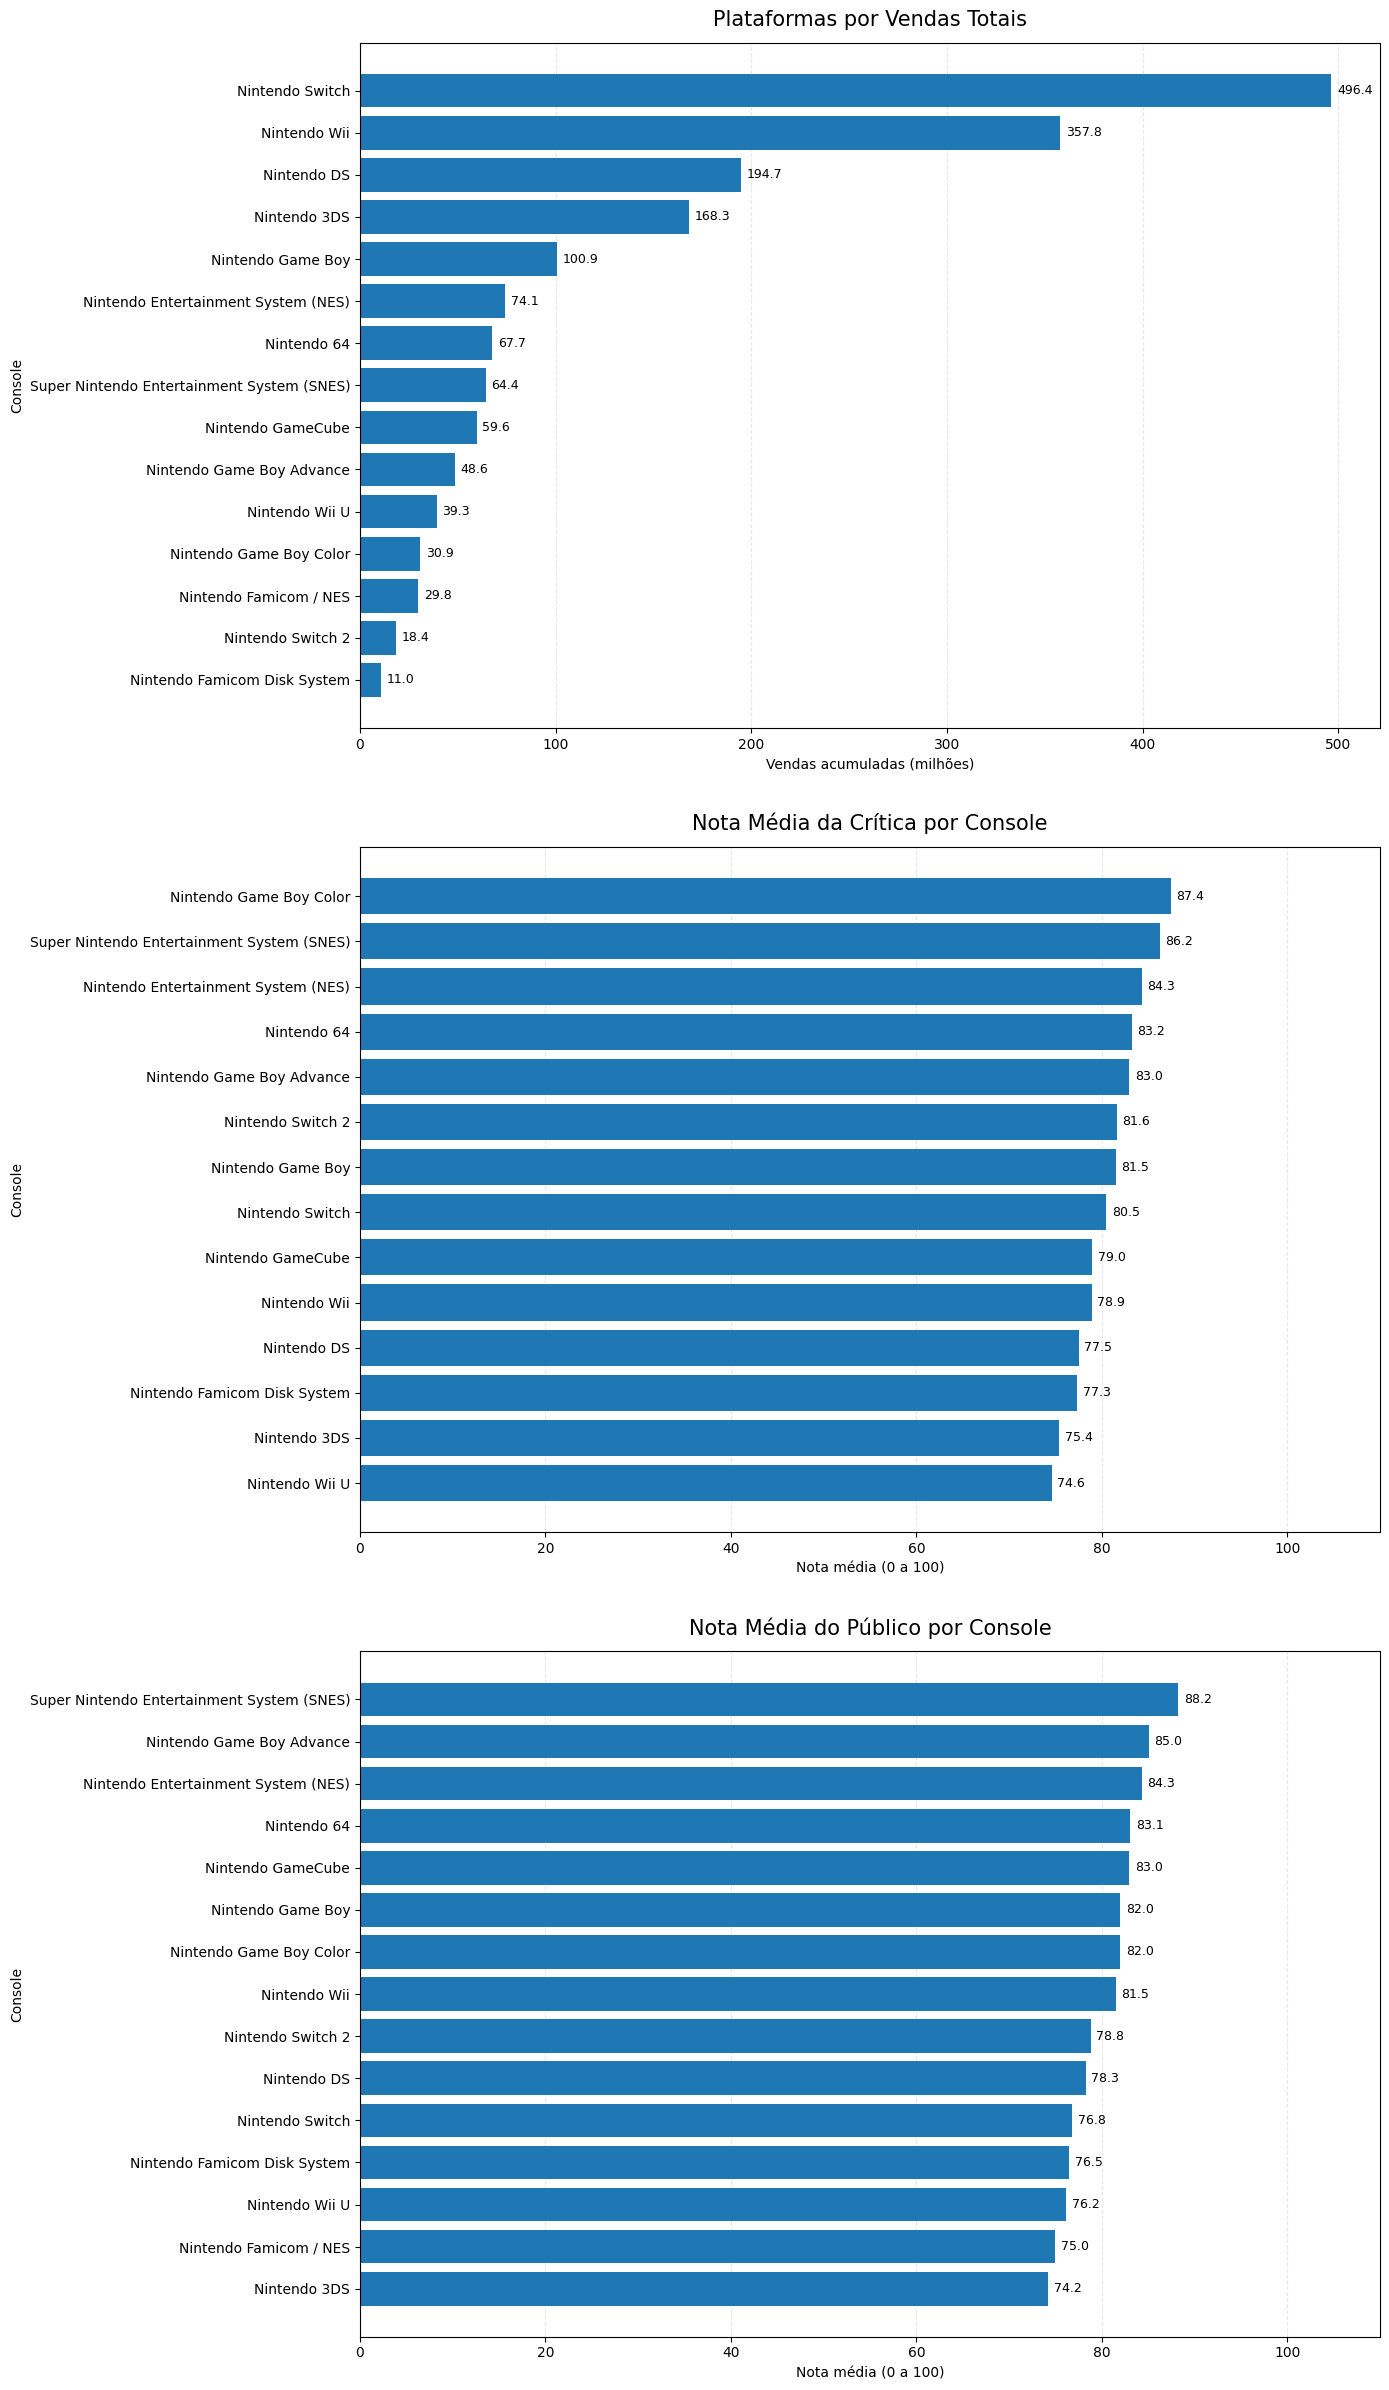

In [58]:




colunas_numericas = [
    "vendas_milhoes",
    "nota_critica_100",
    "nota_publico_100"
]

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

dados = df.copy()

dados["plataforma_original"] = (
    dados["plataforma_original"]
    .astype("string")
    .str.strip()
)

dados = dados[
    dados["plataforma_original"].notna()
    & dados["plataforma_original"].ne("")
]


desempenho = (
    dados.groupby("plataforma_original")
    .agg(
        vendas_totais=("vendas_milhoes", "sum"),
        nota_critica_media=("nota_critica_100", "mean"),
        nota_publico_media=("nota_publico_100", "mean")
    )
)


top_15 = desempenho.nlargest(15, "vendas_totais")


fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 24)
)


vendas = top_15["vendas_totais"].sort_values(ascending=True)

barras1 = axes[0].barh(vendas.index, vendas.values)
axes[0].bar_label(
    barras1,
    labels=[f"{v:,.1f}" for v in vendas.values],
    padding=4,
    fontsize=9
)
axes[0].set_title(
    "Plataformas por Vendas Totais",
    fontsize=15,
    pad=12
)
axes[0].set_xlabel("Vendas acumuladas (milhões)")
axes[0].set_ylabel("Console")
axes[0].grid(axis="x", linestyle="--", alpha=0.3)
axes[0].set_axisbelow(True)


critica = (
    top_15["nota_critica_media"]
    .dropna()
    .sort_values(ascending=True)
)

barras2 = axes[1].barh(critica.index, critica.values)
axes[1].bar_label(
    barras2,
    labels=[f"{v:.1f}" for v in critica.values],
    padding=4,
    fontsize=9
)
axes[1].set_title(
    "Nota Média da Crítica por Console",
    fontsize=15,
    pad=12
)
axes[1].set_xlabel("Nota média (0 a 100)")
axes[1].set_ylabel("Console")
axes[1].set_xlim(0, 110)
axes[1].grid(axis="x", linestyle="--", alpha=0.3)
axes[1].set_axisbelow(True)


publico = (
    top_15["nota_publico_media"]
    .dropna()
    .sort_values(ascending=True)
)

barras3 = axes[2].barh(publico.index, publico.values)
axes[2].bar_label(
    barras3,
    labels=[f"{v:.1f}" for v in publico.values],
    padding=4,
    fontsize=9
)
axes[2].set_title(
    "Nota Média do Público por Console",
    fontsize=15,
    pad=12
)
axes[2].set_xlabel("Nota média (0 a 100)")
axes[2].set_ylabel("Console")
axes[2].set_xlim(0, 110)
axes[2].grid(axis="x", linestyle="--", alpha=0.3)
axes[2].set_axisbelow(True)

plt.tight_layout(h_pad=3)
plt.show()




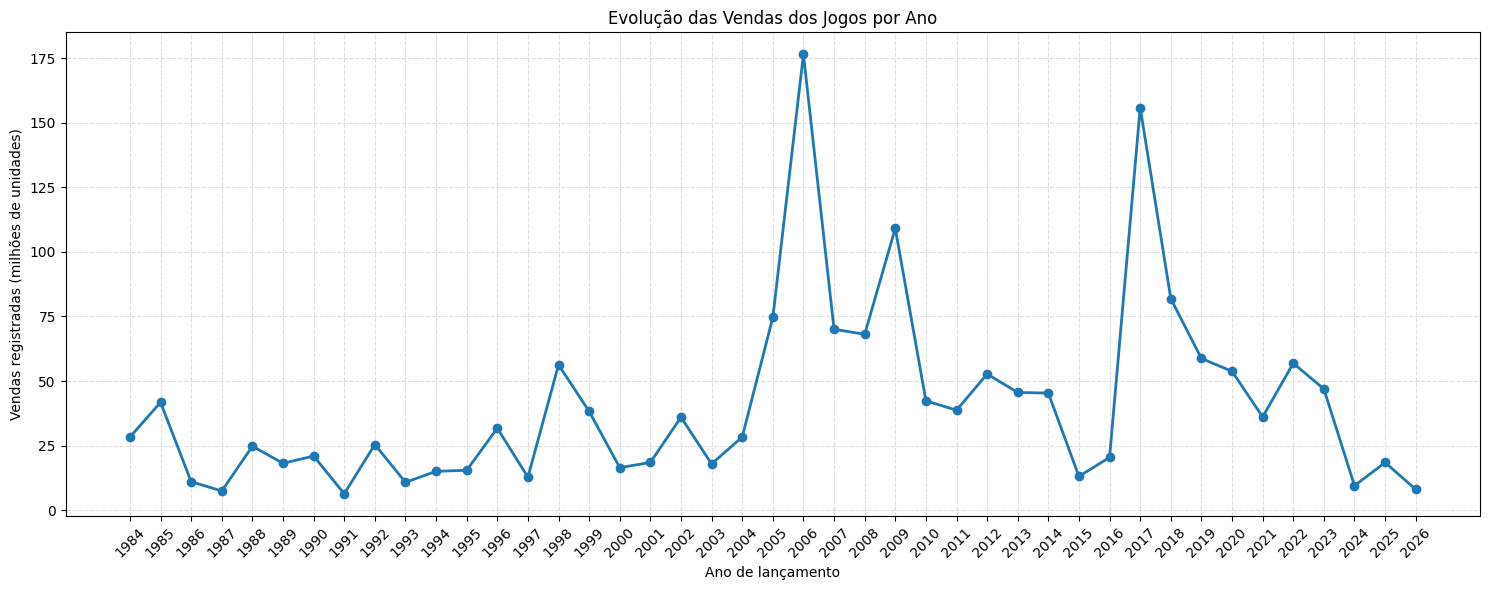

In [26]:



dados = df.copy()

dados["ano_lancamento"] = pd.to_numeric(
    dados["ano_lancamento"], errors="coerce"
)

dados["vendas_milhoes"] = pd.to_numeric(
    dados["vendas_milhoes"], errors="coerce"
)


dados_validos = dados.dropna(
    subset=["ano_lancamento", "vendas_milhoes"]
).copy()

dados_validos["ano_lancamento"] = (
    dados_validos["ano_lancamento"].astype(int)
)


vendas_ano = (
    dados_validos.groupby("ano_lancamento")["vendas_milhoes"]
    .sum()
    .sort_index()
)


plt.figure(figsize=(15, 6))

plt.plot(
    vendas_ano.index,
    vendas_ano.values,
    marker="o",
    linewidth=2
)

plt.title("Evolução das Vendas dos Jogos por Ano")
plt.xlabel("Ano de lançamento")
plt.ylabel("Vendas registradas (milhões de unidades)")
plt.xticks(vendas_ano.index, rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


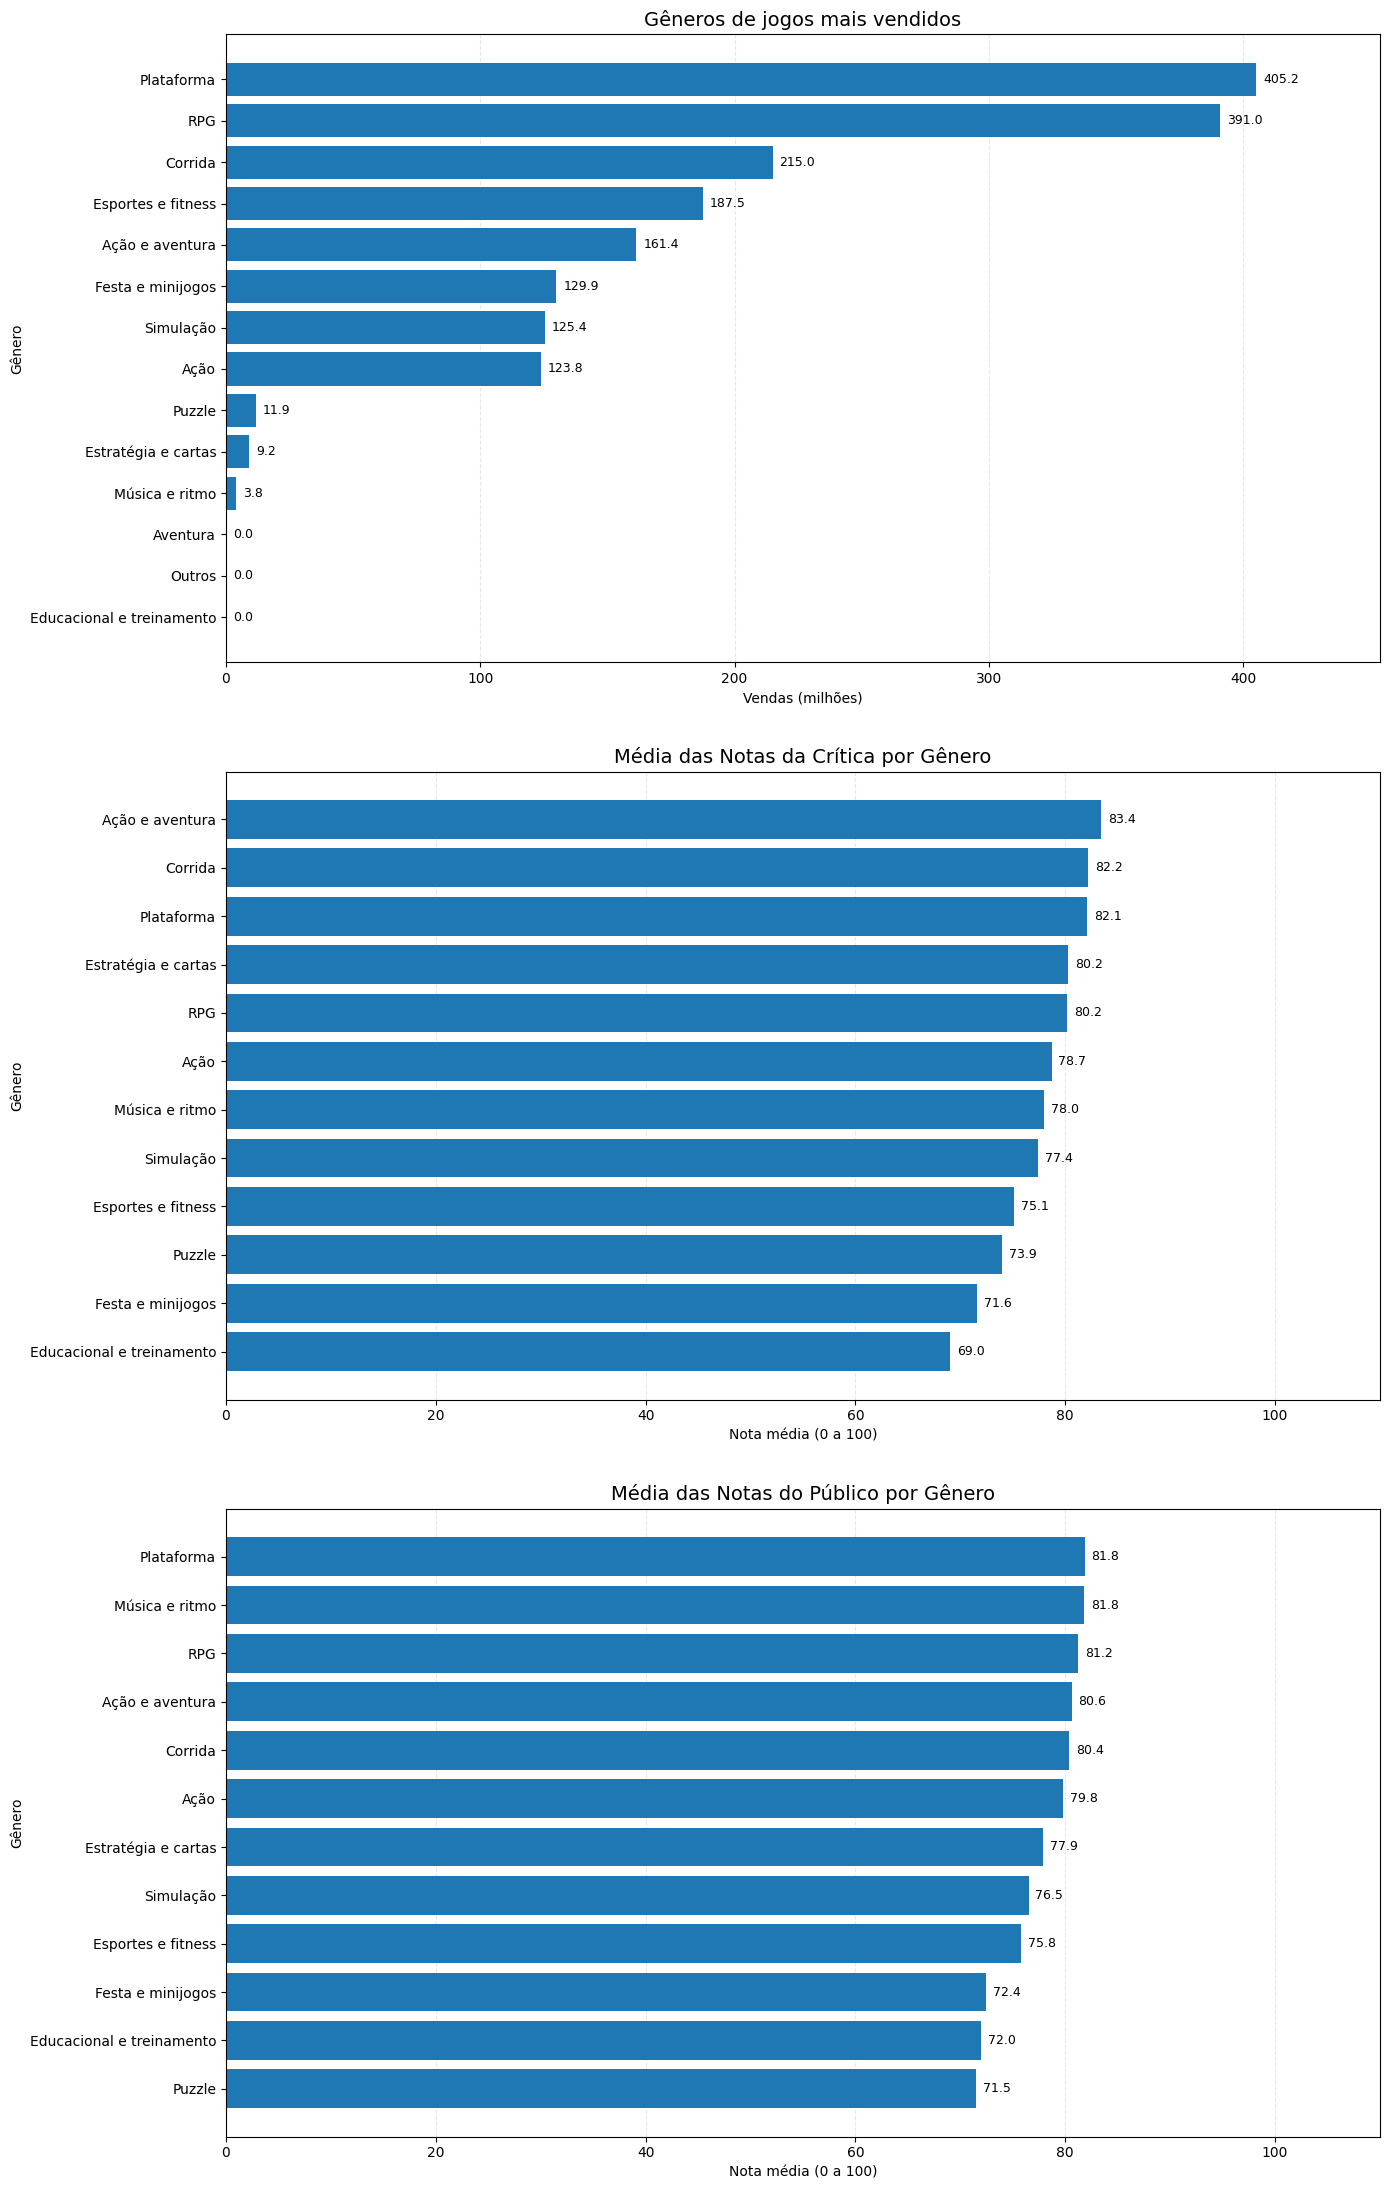

In [18]:



colunas = [
    "vendas_milhoes",
    "nota_critica_100",
    "nota_publico_100"
]

for coluna in colunas:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

dados = df.copy()

dados["genero"] = dados["genero"].astype("string").str.strip()

dados = dados[
    dados["genero"].notna()
    & dados["genero"].ne("")
]


desempenho = (
    dados.groupby("genero")
    .agg(
        vendas_totais=("vendas_milhoes", "sum"),
        nota_critica_media=("nota_critica_100", "mean"),
        nota_publico_media=("nota_publico_100", "mean")
    )
)


top_15 = desempenho.nlargest(15, "vendas_totais")


fig, axes = plt.subplots(3, 1, figsize=(14, 22))


vendas = top_15["vendas_totais"].sort_values(ascending=True)

barras1 = axes[0].barh(vendas.index, vendas.values)

axes[0].bar_label(
    barras1,
    labels=[f"{v:,.1f}" for v in vendas.values],
    padding=5,
    fontsize=9
)

axes[0].set_title("Gêneros de jogos mais vendidos", fontsize=14)
axes[0].set_xlabel("Vendas (milhões)")
axes[0].set_ylabel("Gênero")
axes[0].grid(axis="x", linestyle="--", alpha=0.3)
axes[0].set_axisbelow(True)
axes[0].margins(x=0.12)


critica = (
    top_15["nota_critica_media"]
    .dropna()
    .sort_values(ascending=True)
)

barras2 = axes[1].barh(critica.index, critica.values)

axes[1].bar_label(
    barras2,
    labels=[f"{v:.1f}" for v in critica.values],
    padding=5,
    fontsize=9
)

axes[1].set_title("Média das Notas da Crítica por Gênero", fontsize=14)
axes[1].set_xlabel("Nota média (0 a 100)")
axes[1].set_ylabel("Gênero")
axes[1].set_xlim(0, 110)
axes[1].grid(axis="x", linestyle="--", alpha=0.3)
axes[1].set_axisbelow(True)


publico = (
    top_15["nota_publico_media"]
    .dropna()
    .sort_values(ascending=True)
)

barras3 = axes[2].barh(publico.index, publico.values)

axes[2].bar_label(
    barras3,
    labels=[f"{v:.1f}" for v in publico.values],
    padding=5,
    fontsize=9
)

axes[2].set_title("Média das Notas do Público por Gênero", fontsize=14)
axes[2].set_xlabel("Nota média (0 a 100)")
axes[2].set_ylabel("Gênero")
axes[2].set_xlim(0, 110)
axes[2].grid(axis="x", linestyle="--", alpha=0.3)
axes[2].set_axisbelow(True)


plt.tight_layout(h_pad=3)
plt.show()





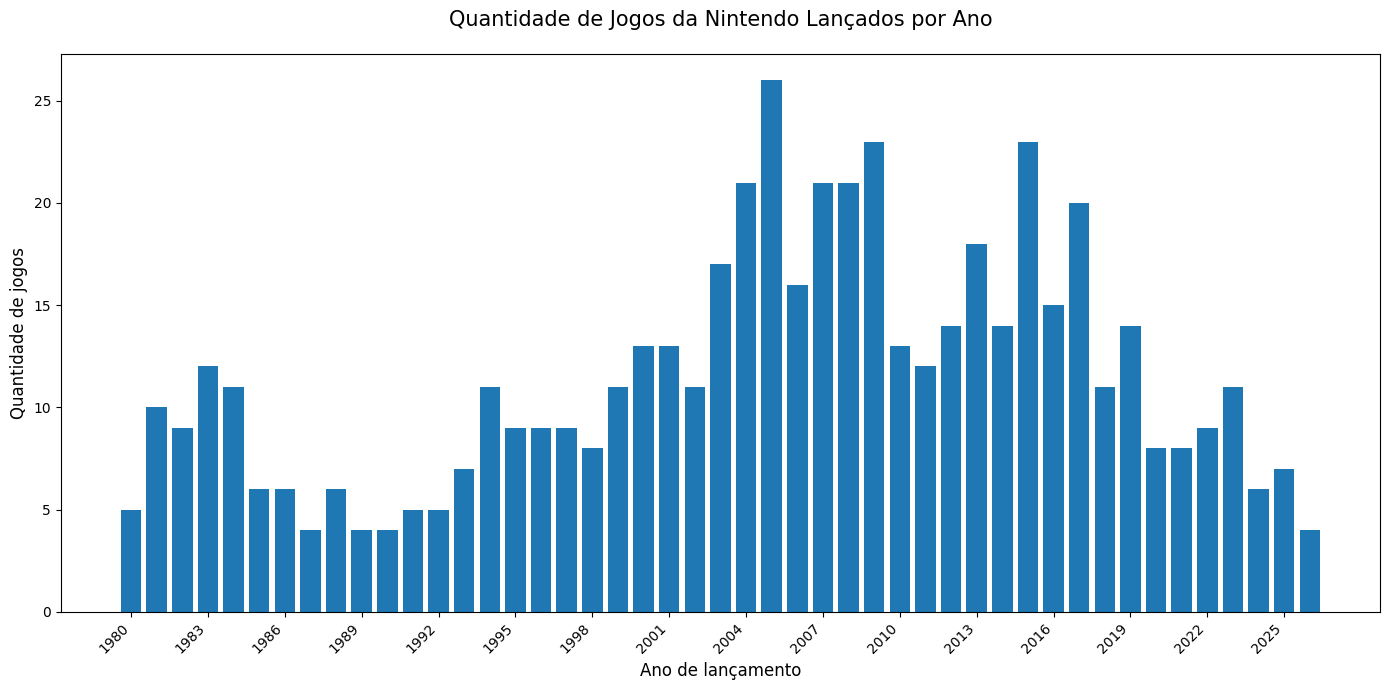

In [21]:


df["ano_lancamento"] = pd.to_numeric(
    df["ano_lancamento"], errors="coerce"
)


dados = df.copy()


dados = dados[
    dados["ano_lancamento"].notna()
    & (dados["ano_lancamento"] > 0)
]


jogos_por_ano = (
    dados.groupby("ano_lancamento")
    .size()
    .sort_index()
)


fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(
    jogos_por_ano.index.astype(int).astype(str),
    jogos_por_ano.values
)


ax.set_title(
    "Quantidade de Jogos da Nintendo Lançados por Ano",
    fontsize=15,
    pad=20
)

ax.set_xlabel("Ano de lançamento", fontsize=12)
ax.set_ylabel("Quantidade de jogos", fontsize=12)


passo = max(1, len(jogos_por_ano) // 15)
ax.set_xticks(
    range(0, len(jogos_por_ano), passo)
)
ax.set_xticklabels(
    jogos_por_ano.index.astype(int).astype(str)[::passo],
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.show()





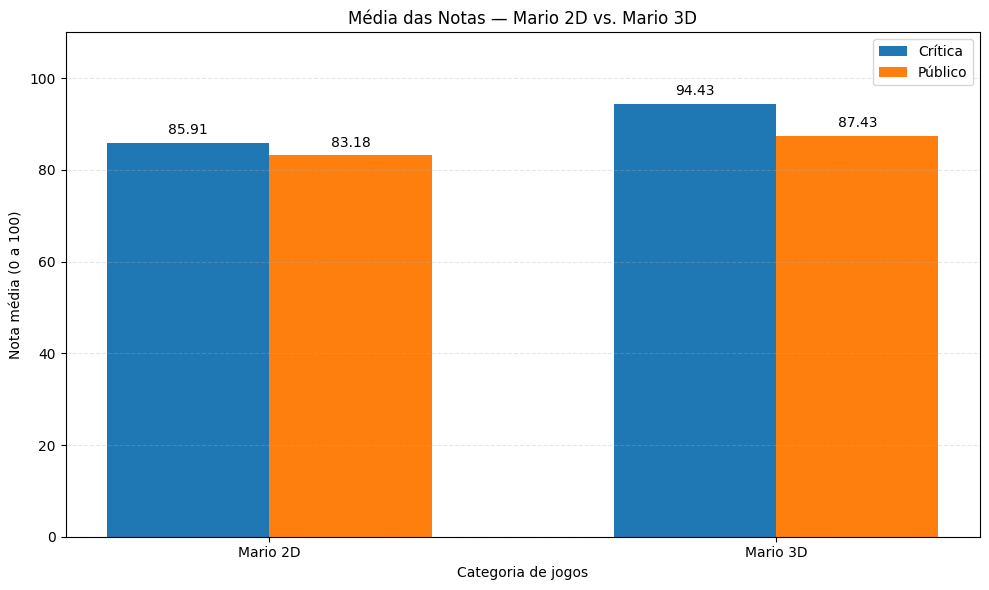

In [ ]:






dados = df.copy()


for coluna in ["nota_critica_100", "nota_publico_100"]:
    dados[coluna] = pd.to_numeric(
        dados[coluna], errors="coerce"
    )


mario = dados[
    dados["franquia_principal"].astype("string").str.strip().str.casefold()
    .eq("mario")
    &
    dados["sub_franquia"].astype("string").str.strip().str.casefold()
    .isin(["mario 2d", "mario 3d"])
].copy()


medias = mario.groupby("sub_franquia")[
    ["nota_critica_100", "nota_publico_100"]
].mean()


ordem = ["Mario 2D", "Mario 3D"]
medias = medias.reindex(ordem)





categorias = ["Mario 2D", "Mario 3D"]
x = np.arange(len(categorias))
largura = 0.32

fig, ax = plt.subplots(figsize=(10, 6))

barras_critica = ax.bar(
    x - largura / 2,
    medias["nota_critica_100"],
    largura,
    label="Crítica"
)

barras_publico = ax.bar(
    x + largura / 2,
    medias["nota_publico_100"],
    largura,
    label="Público"
)


for barras in [barras_critica, barras_publico]:
    ax.bar_label(
        barras,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

ax.set_title("Média das Notas — Mario 2D vs. Mario 3D")
ax.set_ylabel("Nota média (0 a 100)")
ax.set_xlabel("Categoria de jogos")
ax.set_xticks(x)
ax.set_xticklabels(categorias)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


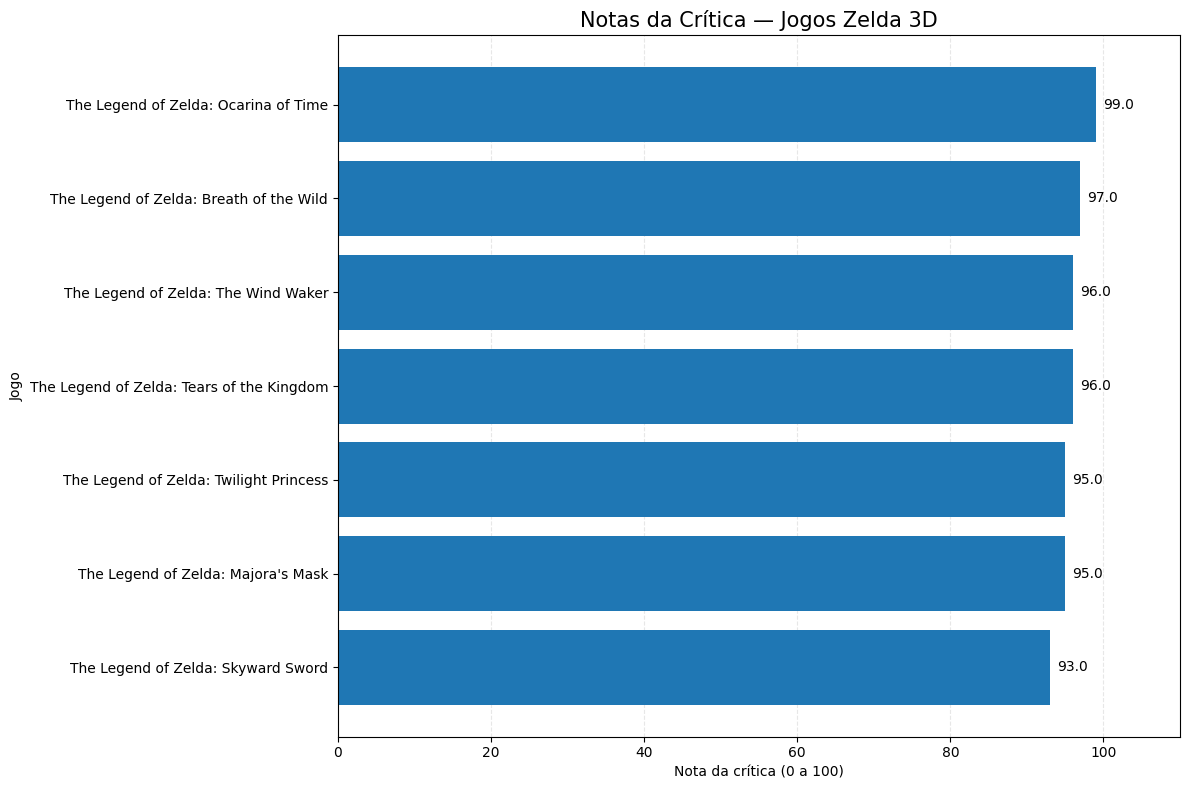

In [ ]:



df["nota_critica_100"] = pd.to_numeric(
    df["nota_critica_100"], errors="coerce"
)


zelda_3d = df[
    df["franquia_principal"].astype("string").str.strip().str.casefold().eq("zelda")
    &
    df["sub_franquia"].astype("string").str.strip().str.casefold().eq("zelda 3d")
].copy()


zelda_3d = zelda_3d.dropna(
    subset=["nota_critica_100", "nome_jogo"]
)


zelda_3d = zelda_3d.sort_values("nota_critica_100")


fig, ax = plt.subplots(figsize=(12, 8))

barras = ax.barh(
    zelda_3d["nome_jogo"],
    zelda_3d["nota_critica_100"]
)


ax.bar_label(
    barras,
    labels=[f"{v:.1f}" for v in zelda_3d["nota_critica_100"]],
    padding=5,
    fontsize=10
)

ax.set_title("Notas da Crítica — Jogos Zelda 3D", fontsize=15)
ax.set_xlabel("Nota da crítica (0 a 100)")
ax.set_ylabel("Jogo")
ax.set_xlim(0, 110)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()





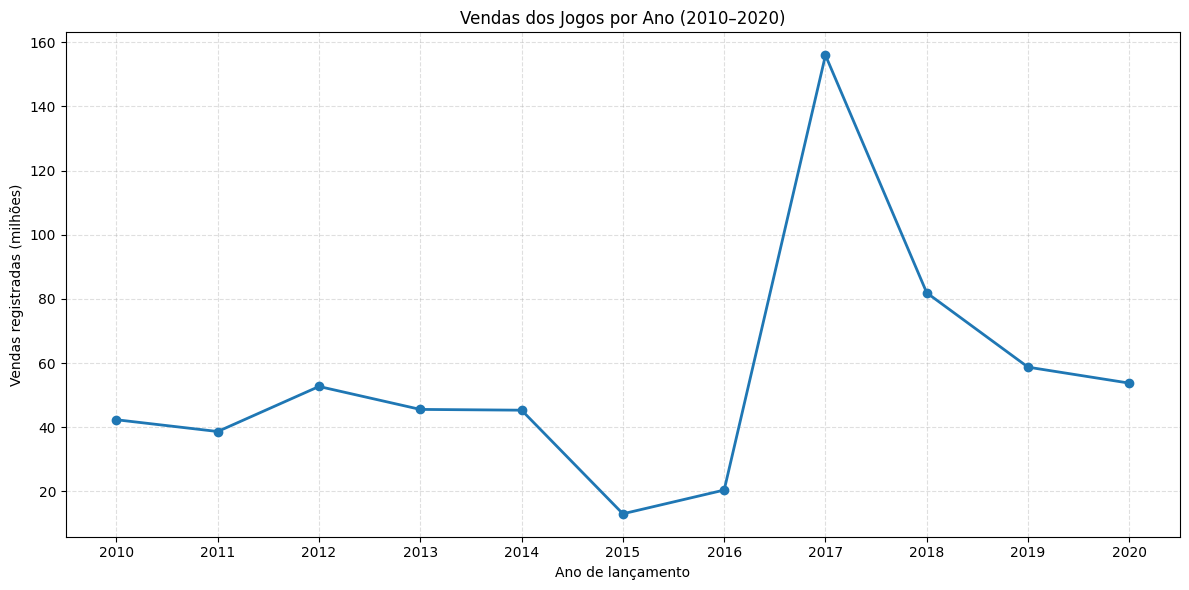

In [ ]:


dados = df.copy()

dados["ano_lancamento"] = pd.to_numeric(
    dados["ano_lancamento"], errors="coerce"
)

dados["vendas_milhoes"] = pd.to_numeric(
    dados["vendas_milhoes"], errors="coerce"
)

periodo = dados[
    dados["ano_lancamento"].between(2010, 2020)
].copy()

vendas_ano = (
    periodo.dropna(subset=["vendas_milhoes"])
    .groupby("ano_lancamento")["vendas_milhoes"]
    .sum()
    .reindex(range(2010, 2021), fill_value=0)
)



plt.figure(figsize=(12, 6))

plt.plot(
    vendas_ano.index,
    vendas_ano.values,
    marker="o",
    linewidth=2
)

plt.title("Vendas dos Jogos por Ano (2010–2020)")
plt.xlabel("Ano de lançamento")
plt.ylabel("Vendas registradas (milhões)")
plt.xticks(range(2010, 2021))
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [ ]:


jogos_acao = (
    df[
        df["genero"].astype("string").str.strip().str.casefold()
        == "ação".casefold()
    ]
    .sort_values(["ano_lancamento", "nome_jogo"])
    .copy()
)

colunas_exibir = [
    "nome_jogo",
    "ano_lancamento",
    "genero",
    "genero_detalhado",
    "franquia_principal",
    "sub_franquia",
    "plataforma_original"
]

print(f"Total de jogos do gênero Ação: {len(jogos_acao)}")

display(jogos_acao[colunas_exibir].reset_index(drop=True))


Total de jogos do gênero Ação: 80


,nome_jogo,ano_lancamento,genero,genero_detalhado,franquia_principal,sub_franquia,plataforma_original
0,Ball,1980,Ação,Arcade LCD,Game & Watch,<NA>,Nintendo Game & Watch
1,Fire,1980,Ação,Ação e reflexos,Game & Watch,<NA>,Nintendo Game & Watch
2,Flagman,1980,Ação,Memorização,Game & Watch,<NA>,Nintendo Game & Watch
3,Judge,1980,Ação,Competição e reflexos,Game & Watch,<NA>,Nintendo Game & Watch
4,Vermin,1980,Ação,Arcade LCD,Game & Watch,<NA>,Nintendo Game & Watch
...,...,...,...,...,...,...,...
75,Hyrule Warriors: Age of Calamity,2020,Ação,Ação musou,Zelda,Hyrule Warriors,Nintendo Switch
76,Kirby Fighters 2,2020,Ação,Luta,Kirby,<NA>,Nintendo Switch
77,Bayonetta 3,2022,Ação,Ação e Hack and slash,Bayonetta,<NA>,Nintendo Switch
78,Fire Emblem Warriors: Three Hopes,2022,Ação,Ação musou,Fire Emblem,Fire Emblem Warriors,Nintendo Switch


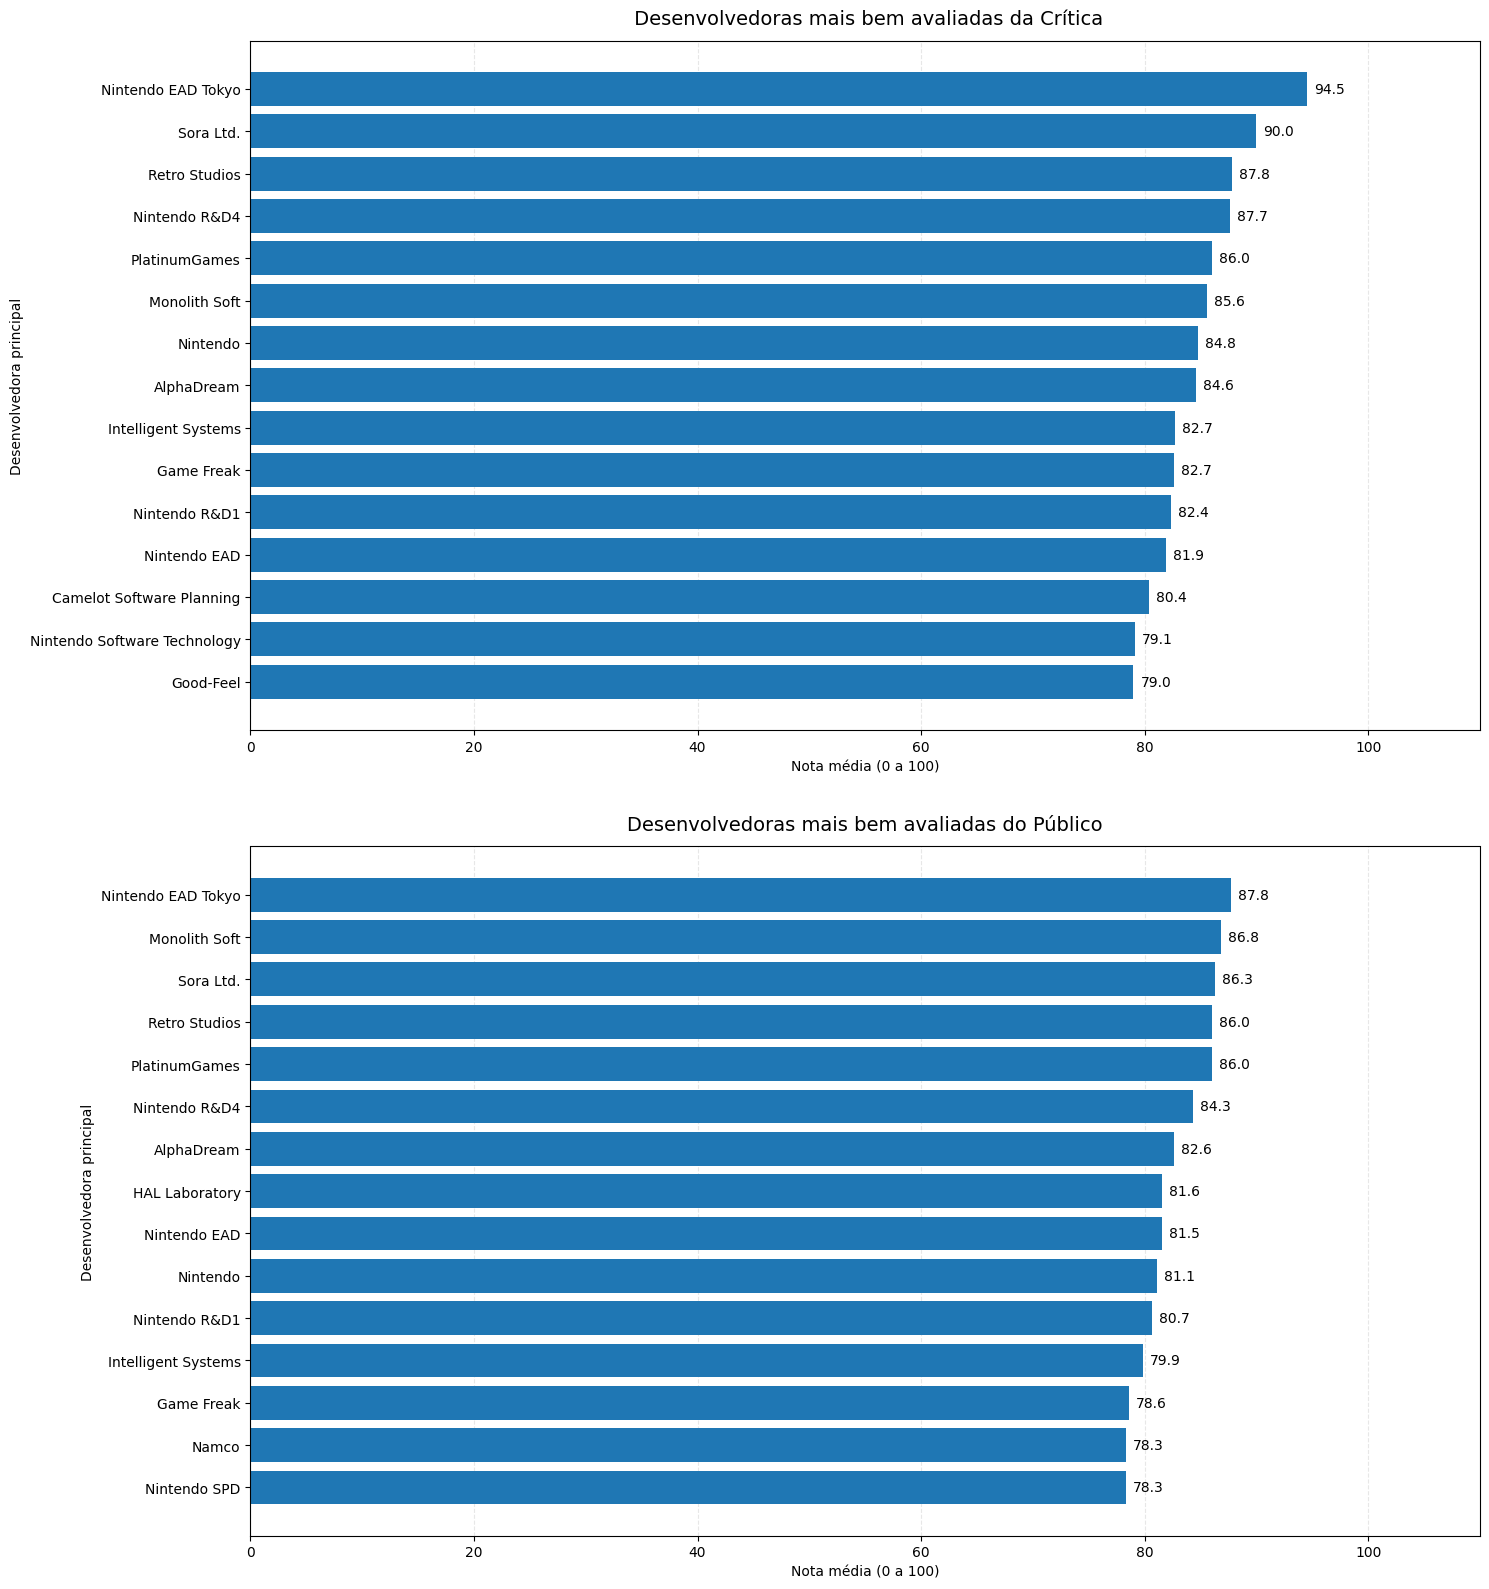

In [29]:








for coluna in ["nota_critica_100", "nota_publico_100"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

dados = df.copy()

dados["desenvolvedora_principal"] = (
    dados["desenvolvedora_principal"]
    .astype("string")
    .str.strip()
)

dados = dados[
    dados["desenvolvedora_principal"].notna()
    & dados["desenvolvedora_principal"].ne("")
]


desenvolvedoras = (
    dados.groupby("desenvolvedora_principal")
    .agg(
        nota_critica_media=("nota_critica_100", "mean"),
        nota_publico_media=("nota_publico_100", "mean"),
        jogos_critica=("nota_critica_100", "count"),
        jogos_publico=("nota_publico_100", "count")
    )
)


desenvolvedoras = desenvolvedoras[
    (desenvolvedoras["jogos_critica"] >= 3)
    & (desenvolvedoras["jogos_publico"] >= 3)
]


top_critica = desenvolvedoras.nlargest(
    15, "nota_critica_media"
).sort_values("nota_critica_media", ascending=True)

top_publico = desenvolvedoras.nlargest(
    15, "nota_publico_media"
).sort_values("nota_publico_media", ascending=True)


fig, axes = plt.subplots(2, 1, figsize=(15, 16))


barras1 = axes[0].barh(
    top_critica.index,
    top_critica["nota_critica_media"]
)

axes[0].bar_label(
    barras1,
    labels=[f"{v:.1f}" for v in top_critica["nota_critica_media"]],
    padding=5,
    fontsize=10
)

axes[0].set_title(
    " Desenvolvedoras mais bem avaliadas da Crítica",
    fontsize=14,
    pad=12
)
axes[0].set_xlabel("Nota média (0 a 100)")
axes[0].set_ylabel("Desenvolvedora principal")
axes[0].set_xlim(0, 110)
axes[0].grid(axis="x", linestyle="--", alpha=0.3)
axes[0].set_axisbelow(True)


barras2 = axes[1].barh(
    top_publico.index,
    top_publico["nota_publico_media"]
)

axes[1].bar_label(
    barras2,
    labels=[f"{v:.1f}" for v in top_publico["nota_publico_media"]],
    padding=5,
    fontsize=10
)

axes[1].set_title(
    "Desenvolvedoras mais bem avaliadas do Público",
    fontsize=14,
    pad=12
)
axes[1].set_xlabel("Nota média (0 a 100)")
axes[1].set_ylabel("Desenvolvedora principal")
axes[1].set_xlim(0, 110)
axes[1].grid(axis="x", linestyle="--", alpha=0.3)
axes[1].set_axisbelow(True)

plt.tight_layout(h_pad=3)
plt.show()


